In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn gradio flask

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Titanic-Dataset.csv")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
df.head()


Dataset loaded successfully
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate rows: 0


In [4]:
df = df.drop_duplicates().copy()

features = [
    "Pclass", "Sex", "Age",
    "SibSp", "Parch", "Fare", "Embarked"
]
X = df[features].copy()
y = df["Survived"].copy()

valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Features shape: (891, 7)
Target shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 712
Testing samples: 179


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]
categorical_features = ["Sex", "Embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully!


In [7]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully")


Logistic Regression model trained successfully


In [9]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Survived", "Survived"],
    zero_division=0
))


Model Accuracy: 80.45%

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.81      0.89      0.85       110
    Survived       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



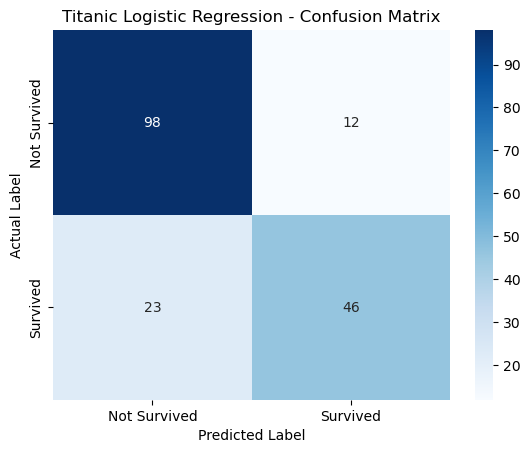

In [10]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Titanic Logistic Regression - Confusion Matrix")
plt.show()


In [11]:
def predict_survival(
    pclass, sex, age, sibsp, parch, fare, embarked
):
    passenger = pd.DataFrame([{
        "Pclass": pclass,
        "Sex": sex,
        "Age": age,
        "SibSp": sibsp,
        "Parch": parch,
        "Fare": fare,
        "Embarked": embarked
    }])
    prediction = int(model.predict(passenger)[0])
    probabilities = model.predict_proba(passenger)[0]

    result = "Survived" if prediction == 1 else "Not Survived"
    confidence = probabilities[prediction] * 100

    return result, confidence


result, confidence = predict_survival(
    3, "male", 22, 0, 0, 7.25, "S"
)

print("Prediction:", result)
print(f"Prediction Confidence: {confidence:.2f}%")


Prediction: Not Survived
Prediction Confidence: 88.94%


In [1]:
import gradio as gr
def gradio_predict(pclass, sex, age, sibsp, parch, fare, embarked):
    result, confidence = predict_survival(
        int(pclass), sex, float(age), int(sibsp),
        int(parch), float(fare), embarked
    )
    return (
        result,
        f"{confidence:.2f}%",
        f"{accuracy * 100:.2f}%"
    )
with gr.Blocks(title="Titanic Survival Prediction") as demo:
    gr.Markdown("# Titanic Survival Prediction System")
    gr.Markdown("Logistic Regression Classification")

    pclass = gr.Dropdown([1, 2, 3], value=3, label="Passenger Class")
    sex = gr.Dropdown(["male", "female"], value="male", label="Sex")
    age = gr.Number(value=22, label="Age")
    sibsp = gr.Number(value=0, label="Siblings/Spouses")
    parch = gr.Number(value=0, label="Parents/Children")
    fare = gr.Number(value=7.25, label="Fare")
    embarked = gr.Dropdown(["S", "C", "Q"], value="S", label="Embarked")
    button = gr.Button("Predict Survival")
    output = gr.Textbox(label="Prediction")
    confidence_out = gr.Textbox(label="Confidence")
    accuracy_out = gr.Textbox(label="Model Test Accuracy")

    button.click(
        gradio_predict,
        inputs=[pclass, sex, age, sibsp, parch, fare, embarked],
        outputs=[output, confidence_out, accuracy_out]
    )

demo.launch()


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


In [2]:
from flask import Flask, request, render_template_string
from threading import Thread
from IPython.display import display, HTML
import time

app = Flask("titanic_app")

page = """
<h1>Titanic Survival Prediction</h1>
<form method="post">
  Passenger Class:
  <select name="pclass">
    <option value="1">First</option>
    <option value="2">Second</option>
    <option value="3" selected>Third</option>
  </select><br><br>

  Sex:
  <select name="sex">
    <option value="male">Male</option>
    <option value="female">Female</option>
  </select><br><br>

  Age: <input type="number" name="age" value="22" min="0" max="100" step="any" required><br><br>
  Siblings/Spouses: <input type="number" name="sibsp" value="0" min="0" required><br><br>
  Parents/Children: <input type="number" name="parch" value="0" min="0" required><br><br>
  Fare: <input type="number" name="fare" value="7.25" min="0" step="any" required><br><br>

  Embarked:
  <select name="embarked">
    <option value="S">Southampton</option>
    <option value="C">Cherbourg</option>
    <option value="Q">Queenstown</option>
  </select><br><br>

  <button type="submit">Predict Survival</button>
</form>

{% if result %}
<h2>Prediction: {{ result }}</h2>
<p>Confidence: {{ confidence }}%</p>
<p>Test Accuracy: {{ accuracy }}%</p>
{% endif %}
"""
@app.route("/", methods=["GET", "POST"])
def home():
    result = None
    confidence = None

    if request.method == "POST":
        try:
            values = [
                int(request.form["pclass"]),
                request.form["sex"],
                float(request.form["age"]),
                int(request.form["sibsp"]),
                int(request.form["parch"]),
                float(request.form["fare"]),
                request.form["embarked"]
            ]

            result, confidence = predict_survival(*values)

        except (ValueError, KeyError):
            return "Please enter valid values.", 400

    return render_template_string(
        page,
        result=result,
        confidence=f"{confidence:.2f}" if confidence is not None else None,
        accuracy=f"{accuracy * 100:.2f}"
    )


def run_flask():
    app.run(host="127.0.0.1", port=5000, debug=False, use_reloader=False)


flask_thread = Thread(target=run_flask, daemon=True)
flask_thread.start()

time.sleep(2)
print("Flask server started on http://127.0.0.1:5000")


 * Serving Flask app 'titanic_app'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


Flask server started on http://127.0.0.1:5000
